# Analysis of DDoS attacks

The `extraction.ipynb` notebook extracts attributes through NLP utilizing LLMs. This notebook is the second part of analyzing the data:
1. Extract Json
2. Group by date and victim (since multiple news stories can attribute to a single attack)
3. Enrich victim with sector (from Wikidata)
4. Push to Neo4j database 
5. Initial analysis

### Import and read data

In [1]:
import os 

files = os.listdir('./')
files

['analysis.ipynb',
 'dashboard',
 'parsed-ext-filtered.csv',
 'wikidata_cache.json']

In [2]:
import pandas as pd

df = pd.read_csv('./parsed-ext-filtered.csv')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12339 entries, 0 to 12338
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Message             12339 non-null  int64  
 1   Date                12339 non-null  str    
 2   Type                12339 non-null  str    
 3   Title               12339 non-null  str    
 4   Content             12339 non-null  str    
 5   Link                12339 non-null  str    
 6   predicted_entities  12331 non-null  str    
 7   elapsed_time        12331 non-null  float64
dtypes: float64(1), int64(1), str(6)
memory usage: 10.4 MB


### Prepare data through JSON extraction

In [4]:
df = df.dropna(subset=['predicted_entities'])
df = df[df['predicted_entities'] != '[]']

In [5]:
df.info()

<class 'pandas.DataFrame'>
Index: 12318 entries, 0 to 12330
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Message             12318 non-null  int64  
 1   Date                12318 non-null  str    
 2   Type                12318 non-null  str    
 3   Title               12318 non-null  str    
 4   Content             12318 non-null  str    
 5   Link                12318 non-null  str    
 6   predicted_entities  12318 non-null  str    
 7   elapsed_time        12318 non-null  float64
dtypes: float64(1), int64(1), str(6)
memory usage: 10.5 MB


In [6]:
df

,Message,Date,Type,Title,Content,Link,predicted_entities,elapsed_time
0,4,2026-10-03,News,Russian hacking group Star Blizzard expands ph...,\r\nRussian hacking group Star Blizzard expand...,https://www.scworld.com/brief/russian-hacking-...,"[{""text"": ""Star Blizzard"", ""type"": ""group"", ""s...",14.744561
1,4,2026-10-03,News,As Baltic states face Russian hybrid aggressio...,\r\nAs Baltic states face Russian hybrid aggre...,https://theconversation.com/as-baltic-states-f...,"[{""text"": ""Estonia"", ""type"": ""location"", ""star...",2.584139
2,4,2026-10-03,News,Ukrainian Startup Osavul Raises $10 Million to...,\r\nUkrainian Startup Osavul Raises $10 Millio...,https://www.kyivpost.com/post/85961,"[{""text"": ""Osavul"", ""type"": ""vitcim"", ""start_p...",3.574570
3,5,2026-10-01,News,Russia escalates VPN blocks following State Du...,\r\nRussia escalates VPN blocks following Stat...,https://www.yahoo.com/news/world/articles/russ...,"[{""text"": ""Russia"", ""type"": ""location"", ""start...",3.255259
4,9,2026-09-30,News,Pro-Russia Hacktivists Increase OT Intrusion C...,\r\nPro-Russia Hacktivists Increase OT Intrusi...,https://www.govinfosecurity.com/pro-russia-hac...,"[{""text"": ""GovInfoSecurity"", ""type"": ""vitcim"",...",3.760031
...,...,...,...,...,...,...,...,...
12326,76103,2015-09-19,Web,Kremlin Blames Recent DDOS on US Hackers,\r\nKremlin Blames Recent DDOS on US Hackers\r...,http://www.hackbusters.com/news/stories/395801...,"[{""text"": ""Kremlin"", ""type"": ""group"", ""start_p...",2.660785
12327,76111,2015-09-19,Web,"Kremlin hit by ""very powerful"" DDoS attack","\r\nKremlin hit by ""very powerful"" DDoS attack...",http://www.itsecurityguru.org/2015/09/18/kreml...,"[{""text"": ""Kremlin"", ""type"": ""vitcim"", ""start_...",2.107107
12328,76113,2015-09-19,News,Kremlin Blames Recent DDOS on US Hackers,\r\nKremlin Blames Recent DDOS on US Hackers\r...,http://news.softpedia.com/news/kremlin-blames-...,"[{""text"": ""Kremlin"", ""type"": ""group"", ""start_p...",3.269920
12329,76122,2015-09-18,Web,Kremlin hit by “very powerful” DDoS attack,\r\nKremlin hit by “very powerful” DDoS attack...,https://www.thecybersecurityplace.com/kremlin-...,"[{""text"": ""Kremlin"", ""type"": ""vitcim"", ""start_...",2.116807


#### Entities as columns

Parse the JSON in `predicted_entities`

In [7]:
import json
from collections import Counter

def parse_entities(raw):
    try:
        parsed = json.loads(raw)
    except (TypeError, ValueError):
        return []
    return parsed if isinstance(parsed, list) else []

In [8]:

ENTITY_TYPES = ['group', 'vitcim', 'location', 'motive', 'person', 'cost', 'url', 'ip']
RENAME = {'vitcim': 'victim'}  # typo in the extraction output

def entities_by_type(raw):
    buckets = {entity_type: [] for entity_type in ENTITY_TYPES}
    for entity in parse_entities(raw):
        bucket = buckets.get(entity.get('type'))
        text = entity.get('text')
        if bucket is not None and text and text not in bucket:
            bucket.append(text)
    return buckets

wide = pd.DataFrame(df['predicted_entities'].map(entities_by_type).tolist(), index=df.index)
wide = wide.rename(columns=RENAME)

stories = df[['Message', 'Date', 'Type', 'Title', 'Link']].join(wide)
stories['Date'] = pd.to_datetime(stories['Date'])

entity_cols = [RENAME.get(t, t) for t in ENTITY_TYPES]
print(f"{len(stories)} stories from {len(df)} rows; stories with at least one entity of each type:")
print(stories[entity_cols].map(len).gt(0).sum().to_string())
stories.head(10)

12318 stories from 12318 rows; stories with at least one entity of each type:
group       8731
victim      8251
location    9521
motive      1976
person      1183
cost         526
url         1974
ip           127


,Message,Date,Type,Title,Link,group,victim,location,motive,person,cost,url,ip
0,4,2026-10-03,News,Russian hacking group Star Blizzard expands ph...,https://www.scworld.com/brief/russian-hacking-...,[Star Blizzard],[],[],[],[],[],[],[]
1,4,2026-10-03,News,As Baltic states face Russian hybrid aggressio...,https://theconversation.com/as-baltic-states-f...,[DDoS],[],"[Estonia, Russia]",[],[],[],[],[]
2,4,2026-10-03,News,Ukrainian Startup Osavul Raises $10 Million to...,https://www.kyivpost.com/post/85961,[],[Osavul],"[Kyiv, Ukrainian]",[],[],[$10 Million],[],[]
3,5,2026-10-01,News,Russia escalates VPN blocks following State Du...,https://www.yahoo.com/news/world/articles/russ...,[],[Yahoo],"[Russia, State Duma]",[],[],[],[],[IP]
4,9,2026-09-30,News,Pro-Russia Hacktivists Increase OT Intrusion C...,https://www.govinfosecurity.com/pro-russia-hac...,[],[GovInfoSecurity],[European Union],[distributed denial-of-service],[],"[4,709]",[],[]
5,12,2026-09-21,News,Russia reports mass cyberattacks targeting ele...,https://www.thehindu.com/news/international/ru...,[],[The Hindu],"[Russia, September 20, 2026]",[],[],"[1,000]",[],[]
6,12,2026-09-21,News,Russia reports mass cyberattacks targeting ele...,https://english.ahram.org.eg/NewsContent/2/8/5...,[DDoS],[Ahram Online],[Russia],[],[],[],[],[]
7,12,2026-09-21,News,Russia reports mass attacks on election system...,https://www.trtworld.com/article/8024e6d522df,[],[],"[Russia, Duma]",[],[],"[1,000]",[],[]
8,12,2026-09-21,News,Russia reports mass cyberattacks targeting ele...,https://www.arabnews.com/world/russia-reports-...,[DDoS],[Arab News],[Russia],[],[],[],[],[]
9,12,2026-09-21,News,United Russia Dominates Russia's Tightly Contr...,https://newscord.org/article/united-russia-dom...,"[United Russia, DDoS]",[],"[Russia, St. Petersburg]",[],[],[],[],[]


#### Locations as countries

Normalise the extracted `location` strings into country names, used both for the attack
events below and for the `country` attribute on the graph nodes.

In [9]:

COUNTRY_ALIASES = {
    'russian': 'Russia', 'russian federation': 'Russia', 'moscow': 'Russia',
    'kremlin': 'Russia', 'st petersburg': 'Russia',
    'ukrainian': 'Ukraine', 'kyiv': 'Ukraine', 'kiev': 'Ukraine', 'crimea': 'Ukraine',
    'us': 'United States', 'u.s': 'United States', 'u s': 'United States',
    'u s a': 'United States', 'usa': 'United States',
    'u.s.a.': 'United States', 'america': 'United States', 'american': 'United States',
    'washington': 'United States',
    'uk': 'United Kingdom', 'u.k': 'United Kingdom', 'u k': 'United Kingdom',
    'great britain': 'United Kingdom', 'britain': 'United Kingdom',
    'british': 'United Kingdom', 'england': 'United Kingdom', 'london': 'United Kingdom',
    'italian': 'Italy', 'rome': 'Italy', 'milan': 'Italy',
    'german': 'Germany', 'berlin': 'Germany',
    'french': 'France', 'paris': 'France',
    'spanish': 'Spain', 'madrid': 'Spain',
    'dutch': 'Netherlands', 'holland': 'Netherlands', 'amsterdam': 'Netherlands',
    'the hague': 'Netherlands',
    'belgian': 'Belgium', 'brussels': 'Belgium',
    'polish': 'Poland', 'warsaw': 'Poland',
    'lithuanian': 'Lithuania', 'vilnius': 'Lithuania',
    'latvian': 'Latvia', 'riga': 'Latvia',
    'estonian': 'Estonia', 'tallinn': 'Estonia',
    'finnish': 'Finland', 'helsinki': 'Finland',
    'swedish': 'Sweden', 'stockholm': 'Sweden',
    'norwegian': 'Norway', 'oslo': 'Norway',
    'danish': 'Denmark', 'copenhagen': 'Denmark',
    'czech': 'Czechia', 'prague': 'Czechia',
    'romanian': 'Romania', 'bucharest': 'Romania',
    'chinese': 'China', 'beijing': 'China',
    'japanese': 'Japan', 'tokyo': 'Japan',
    'korean': 'South Korea', 'south korean': 'South Korea', 'seoul': 'South Korea',
    'north korean': 'North Korea', 'dprk': 'North Korea', 'pyongyang': 'North Korea',
    'iranian': 'Iran', 'tehran': 'Iran',
    'israeli': 'Israel', 'tel aviv': 'Israel', 'jerusalem': 'Israel',
    'indian': 'India', 'new delhi': 'India', 'delhi': 'India',
    'turkish': 'Turkey', 'ankara': 'Turkey', 'istanbul': 'Turkey',
    'australian': 'Australia', 'canberra': 'Australia', 'sydney': 'Australia',
    'canadian': 'Canada', 'ottawa': 'Canada', 'toronto': 'Canada',
    'brazilian': 'Brazil', 'mexican': 'Mexico', 'swiss': 'Switzerland',
    'austrian': 'Austria', 'vienna': 'Austria',
    'greek': 'Greece', 'athens': 'Greece',
    'portuguese': 'Portugal', 'lisbon': 'Portugal',
    'irish': 'Ireland', 'dublin': 'Ireland',
    'belarusian': 'Belarus', 'minsk': 'Belarus', 'moldovan': 'Moldova',
    'georgian': 'Georgia', 'taiwanese': 'Taiwan', 'taipei': 'Taiwan',
    'vietnamese': 'Vietnam', 'indonesian': 'Indonesia', 'pakistani': 'Pakistan',
    'saudi': 'Saudi Arabia', 'emirati': 'United Arab Emirates',
    'uae': 'United Arab Emirates', 'u a e': 'United Arab Emirates',
    'egyptian': 'Egypt', 'nigerian': 'Nigeria', 'south african': 'South Africa',
}

COUNTRY_NAMES = {
    'Afghanistan', 'Albania', 'Algeria', 'Andorra', 'Angola', 'Argentina', 'Armenia',
    'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Bangladesh', 'Barbados', 'Belarus',
    'Belgium', 'Belize', 'Benin', 'Bhutan', 'Bolivia', 'Bosnia And Herzegovina', 'Botswana',
    'Brazil', 'Brunei', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon',
    'Canada', 'Chad', 'Chile', 'China', 'Colombia', 'Congo', 'Costa Rica', 'Croatia', 'Cuba',
    'Cyprus', 'Czechia', 'Czech Republic', 'Denmark', 'Dominican Republic', 'Ecuador',
    'Egypt', 'El Salvador', 'Estonia', 'Eswatini', 'Ethiopia', 'Fiji', 'Finland', 'France',
    'Gabon', 'Gambia', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea',
    'Guyana', 'Haiti', 'Honduras', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Iran',
    'Iraq', 'Ireland', 'Israel', 'Italy', 'Ivory Coast', 'Jamaica', 'Japan', 'Jordan',
    'Kazakhstan', 'Kenya', 'Kosovo', 'Kuwait', 'Kyrgyzstan', 'Laos', 'Latvia', 'Lebanon',
    'Liberia', 'Libya', 'Liechtenstein', 'Lithuania', 'Luxembourg', 'Madagascar', 'Malawi',
    'Malaysia', 'Maldives', 'Mali', 'Malta', 'Mauritania', 'Mauritius', 'Mexico', 'Moldova',
    'Monaco', 'Mongolia', 'Montenegro', 'Morocco', 'Mozambique', 'Myanmar', 'Namibia',
    'Nepal', 'Netherlands', 'New Zealand', 'Nicaragua', 'Niger', 'Nigeria', 'North Korea',
    'North Macedonia', 'Norway', 'Oman', 'Pakistan', 'Palestine', 'Panama', 'Papua New Guinea',
    'Paraguay', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Qatar', 'Romania', 'Russia',
    'Rwanda', 'San Marino', 'Saudi Arabia', 'Senegal', 'Serbia', 'Singapore', 'Slovakia',
    'Slovenia', 'Somalia', 'South Africa', 'South Korea', 'South Sudan', 'Spain',
    'Sri Lanka', 'Sudan', 'Suriname', 'Sweden', 'Switzerland', 'Syria', 'Taiwan',
    'Tajikistan', 'Tanzania', 'Thailand', 'Togo', 'Trinidad And Tobago', 'Tunisia',
    'Turkey', 'Turkmenistan', 'Uganda', 'Ukraine', 'United Arab Emirates', 'United Kingdom',
    'United States', 'Uruguay', 'Uzbekistan', 'Venezuela', 'Vietnam', 'Yemen', 'Zambia',
    'Zimbabwe',
}
COUNTRY_LOOKUP = {name.lower(): name for name in COUNTRY_NAMES}


def to_country(location):
    if not isinstance(location, str):
        return None
    key = ' '.join(location.strip().strip('.,').lower().split())
    if not key:
        return None
    if key in COUNTRY_ALIASES:
        return COUNTRY_ALIASES[key]
    return COUNTRY_LOOKUP.get(key)


def countries_of(locations):
    out = []
    for location in locations:
        country = to_country(location)
        if country and country not in out:
            out.append(country)
    return out

### Group stories into attack events

In [10]:
WINDOW_DAYS = 7  
MAX_SPAN_DAYS = 30 
NAME_SIMILARITY = 0.90

In [11]:
import re
import unicodedata
from difflib import SequenceMatcher

LEGAL_SUFFIXES = {
    'inc', 'llc', 'ltd', 'limited', 'plc', 'corp', 'corporation', 'company', 'co', 'group',
    'holding', 'holdings', 'gmbh', 'ag', 'sa', 'sas', 'spa', 'srl', 'bv', 'nv', 'as', 'ab',
    'oy', 'oyj', 'aps', 'kg', 'pty', 'sl', 'sarl',
}

NOISE_TARGETS = {
    'users', 'customers', 'citizens', 'government', 'governments', 'websites', 'website',
    'servers', 'server', 'companies', 'company', 'organisations', 'organizations', 'banks',
    'bank', 'airports', 'airport', 'hospitals', 'hospital', 'ministry', 'ministries',
    'police', 'military', 'army', 'public', 'users accounts', 'internet', 'victims',
    'victim', 'target', 'targets', 'unknown', 'n a', 'none', 'ddos', 'ddos attack',
}

# Publishers and research vendors: these appear as "victims" in the data only because they wrote the story and need to be excluded.
MEDIA_SOURCES = {
    'bleeping computer', 'bleepingcomputer', 'cybernews', 'infosecurity magazine',
    'infosecurity', 'recorded future', 'the record', 'securityweek', 'security week',
    'security affairs', 'the hacker news', 'hackread', 'dark reading', 'darkreading',
    'sc media', 'sc magazine', 'scmagazine', 'threatpost', 'cyberscoop', 'cyberwire',
    'the cyberwire', 'the register', 'zdnet',
    'techcrunch', 'ars technica', 'wired', 'reuters', 'associated press', 'ap news',
    'bloomberg', 'cnn', 'bbc', 'bbc news', 'the guardian', 'new york times',
    'washington post', 'wall street journal', 'forbes', 'politico', 'euronews',
    'kyiv post', 'kyiv independent', 'moscow times', 'tass', 'ria novosti', 'interfax',
    'yahoo', 'yahoo news', 'msn', 'google news', 'medium', 'oodaloop', 'ooda loop',
    'help net security', 'gbhackers', 'cyber security news', 'industrial cyber',
    'the conversation', 'anadolu agency', 'al jazeera', 'deutsche welle', 'france 24',
}


def normalise_name(name):
    text = unicodedata.normalize('NFKD', name)
    text = ''.join(char for char in text if not unicodedata.combining(char))
    text = re.sub(r'[^0-9a-zA-Z]+', ' ', text).lower().strip()
    tokens = [token for token in text.split() if token not in LEGAL_SUFFIXES]
    if tokens and tokens[0] == 'the':
        tokens = tokens[1:]
    return ' '.join(tokens)


def is_noise_target(normalised):
    return (not normalised or len(normalised) < 3 or normalised.isdigit()
            or normalised in NOISE_TARGETS or normalised in MEDIA_SOURCES)


def build_canonical_map(names):

    counts = Counter(names)
    canonical_of_normalised = {}
    blocks = {} 

    for name, _ in counts.most_common():
        normalised = normalise_name(name)
        if is_noise_target(normalised) or normalised in canonical_of_normalised:
            continue
        block_key = normalised.split()[0]
        block = blocks.setdefault(block_key, [])
        match = next(
            (candidate for candidate in block
             if SequenceMatcher(None, normalised, candidate).ratio() >= NAME_SIMILARITY
             or set(normalised.split()) <= set(candidate.split())
             or set(candidate.split()) <= set(normalised.split())),
            None,
        )
        if match is None:
            block.append(normalised)
            canonical_of_normalised[normalised] = name
        else:
            canonical_of_normalised[normalised] = canonical_of_normalised[match]

    return {name: canonical_of_normalised.get(normalise_name(name)) for name in counts}


all_targets = [name for column in ('victim', 'person') for names in stories[column] for name in names]
canonical_target = build_canonical_map(all_targets)
resolved = {name: canonical for name, canonical in canonical_target.items() if canonical}
print(f"{len(canonical_target)} raw target names -> {len(set(resolved.values()))} canonical targets "
      f"({len(canonical_target) - len(resolved)} dropped as generic)")

4820 raw target names -> 3962 canonical targets (135 dropped as generic)


In [12]:
def union(values, into):

    for value in values:
        if value not in into:
            into.append(value)
    return into


mentions = {}
for index, story in stories.iterrows():
    for column, label in (('victim', 'Victim'), ('person', 'Person')):
        for name in story[column]:
            canonical = canonical_target.get(name)
            if canonical:
                mentions.setdefault((label, canonical), []).append((story['Date'], index, name))

attack_events = []
for (label, canonical), rows in mentions.items():
    rows.sort()
    cluster = []
    for date, index, raw_name in rows:
        if cluster and ((date - cluster[-1][0]).days > WINDOW_DAYS
                        or (date - cluster[0][0]).days > MAX_SPAN_DAYS):
            attack_events.append((label, canonical, cluster))
            cluster = []
        cluster.append((date, index, raw_name))
    if cluster:
        attack_events.append((label, canonical, cluster))

AGGREGATED = ['group', 'motive', 'cost', 'url', 'ip', 'location']

events = []
for event_number, (label, canonical, cluster) in enumerate(sorted(attack_events, key=lambda e: e[2][0][0])):
    rows = [index for _, index, _ in cluster]
    event = stories.loc[rows]
    aggregated = {column: union([v for values in event[column] for v in values], []) for column in AGGREGATED}
    events.append({
        'event_id': f"E{event_number:06d}",
        'target_label': label,
        'target_name': canonical,
        'target_aliases': union([raw_name for _, _, raw_name in cluster], []),
        'first_seen': cluster[0][0],
        'last_seen': cluster[-1][0],
        'n_stories': len(rows),
        'rows': rows,
        'message_ids': union([int(v) for v in event['Message']], []),
        'titles': union([t for t in event['Title'] if isinstance(t, str)], []),
        'links': union([l for l in event['Link'] if isinstance(l, str)], []),
        'countries': countries_of(aggregated['location']),
        **{f"{column}s": values for column, values in aggregated.items()},
    })

attack_events = pd.DataFrame(events)
attack_events['span_days'] = (attack_events['last_seen'] - attack_events['first_seen']).dt.days

print(f"{len(stories)} stories -> {len(attack_events)} attack events "
      f"({attack_events['n_stories'].sum()} target-story mentions)")
print(f"{(attack_events['n_stories'] > 1).sum()} events are reported by more than one story; "
      f"largest has {attack_events['n_stories'].max()}")
attack_events.head()

12318 stories -> 7076 attack events (11509 target-story mentions)
1816 events are reported by more than one story; largest has 67


,event_id,target_label,target_name,target_aliases,first_seen,last_seen,n_stories,rows,message_ids,titles,links,countries,groups,motives,costs,urls,ips,locations,span_days
0,E000000,Victim,Washington Examiner,[Washington Examiner],2015-09-16,2015-09-16,1,[12319],[75873],"[California hackers attack Kremlin, Putin's we...",[http://www.washingtonexaminer.com/california-...,"[Russia, United States]",[],[],[],[],[],"[California, Kremlin, United States]",0
1,E000001,Person,Churov,[Churov],2015-09-16,2015-09-16,1,[12319],[75873],"[California hackers attack Kremlin, Putin's we...",[http://www.washingtonexaminer.com/california-...,"[Russia, United States]",[],[],[],[],[],"[California, Kremlin, United States]",0
2,E000002,Person,Putin,[Putin],2015-09-17,2015-09-17,1,[12318],[75871],"[Russia: California hackers attack Kremlin, Pu...",[https://www.oodaloop.com/osint/cyber/2015/09/...,[Russia],[OODA Loop],[],[],[],[],"[Russia, California, Kremlin]",0
3,E000003,Person,Vladimir Putin,[Vladimir Putin],2015-09-18,2015-09-20,2,"[12330, 12314]","[76123, 75764]",[DDoS attacks hit The Kremlin and Vladimir Put...,[http://www.itproportal.com/2015/09/18/ddos-at...,[],[DDoS],[],[],[],[],[The Kremlin],2
4,E000004,Victim,Kremlin,[Kremlin],2015-09-18,2015-09-19,2,"[12329, 12327]","[76122, 76111]","[Kremlin hit by “very powerful” DDoS attack, K...",[https://www.thecybersecurityplace.com/kremlin...,[],[DDoS],[],[],[],[],[],1


In [13]:

print('stories per event:')
print(attack_events['n_stories'].value_counts().sort_index().head(10).to_string())

biggest = attack_events.loc[attack_events['n_stories'].idxmax()]
print(f"\nbiggest event: {biggest['target_name']} ({biggest['target_label']}), "
      f"{biggest['first_seen'].date()} .. {biggest['last_seen'].date()}, "
      f"{biggest['n_stories']} stories, groups={biggest['groups'][:5]}")
for title in biggest['titles'][:10]:
    print('  -', title[:100])

stories per event:
n_stories
1     5260
2     1213
3      246
4      129
5       52
6       37
7       25
8       14
9       12
10      11

biggest event: European Parliament (Victim), 2022-11-23 .. 2022-11-30, 67 stories, groups=['pro-Russia', 'DDoS', 'Distributed Denial of Service', 'Anonymous Russia', 'pro-Russia group']
  - European Parliament website knocked out by pro-Russia DDoS attack -
  - Pro-Russian hacktivists take down EU Parliament site in DDoS attack -
  - European Parliament website hit by cyberattack after Russian terrorism vote
  - European Parliament declares Russia a terrorism sponsor, then its site goes
  - European Parliament faces cyberattack from pro-Russia group after terrorism
  - European Parliament website affected by hacking attack by pro-Moscow group
  - Сайт Европарламента подвергся DDoS‑атаке; ответственность за нее взяли ...
  - European Parliament website hit by DDoS attack after voting to declare
  - European Parliament attacked by hackers after vote 

In [14]:

repeat_targets = (attack_events.groupby(['target_label', 'target_name'])
                  .agg(events=('event_id', 'size'), stories=('n_stories', 'sum'))
                  .sort_values('events', ascending=False))
print(repeat_targets.head(10).to_string())

example = repeat_targets.index[0]
print(f"\nevents for {example[1]}:")
print(attack_events[(attack_events['target_label'] == example[0])
                    & (attack_events['target_name'] == example[1])]
      [['event_id', 'first_seen', 'last_seen', 'span_days', 'n_stories', 'groups']]
      .head(10).to_string(index=False))

                                  events  stories
target_label target_name                         
Victim       Cloudflare               49      107
             Microsoft                45      116
             Kaspersky                44      109
             DDoS-Guard               35       90
             Google                   35       90
             Telegram                 29      100
             Ukraine                  29       84
             Roskomnadzor             28       63
             The Register             25       32
             Ministry of Defense      24       42

events for Cloudflare:
event_id first_seen  last_seen  span_days  n_stories                      groups
 E000288 2017-08-16 2017-08-19          3          5                      [DDoS]
 E000510 2018-04-14 2018-04-19          5          3 [Coala, SESTA, Boing Boing]
 E000794 2020-07-27 2020-07-29          2          3                          []
 E000881 2021-01-17 2021-01-17          0          1

### Victim sectors from Wikidata

The dataset says nothing about what a victim *is*, so the sector comes from an external
source: the [Wikidata](https://www.wikidata.org) API/
Per victim:

1. `wbsearchentities` finds candidate entities for the name; a candidate is accepted only if
   its label is at least `MATCH_THRESHOLD` similar to the victim name, which keeps
   `wbsearchentities` from attaching a loosely related entity to an unknown victim.
2. `wbgetentities` reads the accepted entity's **instance of** (P31), **industry** (P452),
   **country** (P17) and English description.
3. Those claim labels and the description are matched against `SECTOR_RULES` to land on one
   sector from a fixed taxonomy.
4. Victims with no usable Wikidata match fall back to the same rules applied to the victim's
   own name, which catches the self-describing ones (`... Airport`, `Bank of ...`,
   `Ministry of ...`). The result records which path was used in `sector_source`, so
   rule-based guesses stay separable from sourced ones.

In [15]:
import re

SECTOR_RULES = [
    ('Defense', ['military', 'armed forces', 'army', 'navy', 'air force', 'defence',
                 'defense', 'intelligence agency', 'nato', 'arms industry', 'weapon']),
    ('Government', ['ministry', 'government', 'parliament', 'municipality', 'municipal',
                    'city council', 'public authority', 'state agency', 'federal agency',
                    'police', 'customs', 'tax', 'court', 'election', 'embassy', 'senate',
                    'chancellery', 'prefecture', 'public administration', 'state duma',
                    'civil service', 'regulator', 'agency of', 'federal service']),
    ('Finance', ['bank', 'banking', 'insurance', 'financial', 'finance', 'investment',
                 'stock exchange', 'payment', 'credit union', 'fintech', 'pension',
                 'cryptocurrency', 'asset management', 'brokerage']),
    ('Healthcare', ['hospital', 'health', 'clinic', 'pharmaceutical', 'medical',
                    'healthcare', 'medicine', 'biotechnology']),
    ('Energy & Utilities', ['energy', 'electric', 'electricity', 'power station', 'oil',
                            'natural gas', 'petroleum', 'nuclear', 'water supply',
                            'utility', 'mining', 'renewable', 'pipeline', 'refinery']),
    ('Transport & Logistics', ['airport', 'airline', 'aviation', 'railway', 'railroad',
                               'seaport', 'port', 'shipping', 'logistics', 'transport',
                               'metro', 'bus company', 'postal', 'delivery', 'maritime',
                               'freight', 'ferry', 'toll']),
    ('Telecom', ['telecommunication', 'mobile network', 'internet service provider',
                 'broadband', 'telephone', 'mobile phone operator', 'satellite']),
    ('Technology', ['software', 'information technology', 'computer', 'internet company',
                    'cloud computing', 'cybersecurity', 'computer security', 'technology company',
                    'semiconductor', 'video game', 'web hosting', 'data center', 'web service',
                    'search engine', 'social network', 'online service', 'website']),
    ('Media', ['newspaper', 'broadcast', 'television', 'radio', 'news agency', 'magazine',
               'publisher', 'media', 'press agency', 'journalism', 'news website']),
    ('Education & Research', ['university', 'school', 'college', 'education', 'research institute',
                              'academy', 'institute of technology', 'research centre',
                              'research center', 'library']),
    ('Retail & E-commerce', ['retail', 'supermarket', 'e-commerce', 'online marketplace',
                             'department store', 'restaurant chain', 'fashion', 'grocery',
                             'shopping']),
    ('Manufacturing', ['manufacturer', 'manufacturing', 'automotive', 'aerospace', 'steel',
                       'chemical', 'machinery', 'food processing', 'brewery', 'factory',
                       'industrial', 'shipbuilding', 'engineering company', 'construction']),
    ('Hospitality & Tourism', ['hotel', 'tourism', 'travel agency', 'casino', 'resort',
                               'restaurant']),
    ('Sports', ['football club', 'sports', 'stadium', 'olympic', 'sports league',
                'sports team']),
    ('Politics & NGO', ['political party', 'non-governmental', 'nonprofit', 'charity',
                        'trade union', 'think tank', 'foundation', 'advocacy']),
    ('Religion', ['church', 'religious', 'mosque', 'synagogue', 'diocese']),
    ('Professional Services', ['law firm', 'consulting', 'accounting', 'advertising',
                               'recruitment', 'audit']),
]

ORG_EVIDENCE = [
    'company', 'corporation', 'enterprise', 'business', 'agency', 'organization',
    'organisation', 'institution', 'institute', 'bank', 'university', 'school', 'college',
    'newspaper', 'magazine', 'channel', 'station', 'broadcaster', 'publisher', 'airline',
    'airport', 'operator', 'provider', 'ministry', 'government', 'department', 'authority',
    'club', 'team', 'hospital', 'clinic', 'website', 'portal', 'retailer', 'manufacturer',
    'party', 'association', 'union', 'federation', 'foundation', 'charity', 'port',
    'railway', 'utility', 'telecommunications', 'operator', 'chain', 'group', 'firm',
    'exchange', 'insurer', 'cooperative', 'council', 'parliament', 'police', 'military',
    'service', 'network', 'provider', 'imageboard', 'forum', 'marketplace', 'platform',
]


def word_matcher(keywords):
    pattern = '|'.join(re.escape(keyword) for keyword in sorted(keywords, key=len, reverse=True))
    return re.compile(rf'(?<![a-z]){pattern}(?![a-z])').search


SECTOR_MATCHERS = [(sector, word_matcher(keywords)) for sector, keywords in SECTOR_RULES]
ORG_MATCHER = word_matcher(ORG_EVIDENCE)


def haystack_of(texts):
    return ' | '.join(text.lower() for text in texts if isinstance(text, str) and text)


def classify_sector(texts):
    haystack = haystack_of(texts)
    if not haystack:
        return None
    for sector, matches in SECTOR_MATCHERS:
        if matches(haystack):
            return sector
    return None


def looks_like_organisation(texts):
    return bool(ORG_MATCHER(haystack_of(texts)))

In [ ]:
from pathlib import Path
import time
import requests

WIKIDATA_API = 'https://www.wikidata.org/w/api.php'

MATCH_THRESHOLD = 0.85   
REQUEST_PAUSE = 0.5    
MAX_RETRIES = 8         

SESSION = requests.Session()
SESSION.headers['User-Agent'] = (
    'economics-of-cybersec-research/1.0 python-requests'
)



In [34]:
def api(**params):
    delay = 2.0
    for attempt in range(MAX_RETRIES):
        response = SESSION.get(WIKIDATA_API,
                               params={'format': 'json', **params}, timeout=30)
        if response.status_code in (429, 503) or 'maxlag' in response.text[:200]:
            wait = float(response.headers.get('Retry-After', delay))
            time.sleep(wait)
            delay = min(delay * 2, 60)
            continue
        response.raise_for_status()
        time.sleep(REQUEST_PAUSE)
        return response.json()
    raise RuntimeError(f"API still throttling after {MAX_RETRIES} attempts: {params}")


CLAIM_PROPERTIES = {'P31': 'instance_of', 'P452': 'industry', 'P17': 'country'}


def entity_record(entity):
    claims = entity.get('claims', {})
    record = {'label': entity.get('labels', {}).get('en', {}).get('value'),
              'description': entity.get('descriptions', {}).get('en', {}).get('value')}
    for prop, field in CLAIM_PROPERTIES.items():
        values = []
        for claim in claims.get(prop, []):
            value = claim.get('mainsnak', {}).get('datavalue', {}).get('value')
            if isinstance(value, dict) and value.get('id'):
                values.append(value['id'])
        record[field] = values
    return record

META_ITEMS = {'Q4167410', 'Q13406463', 'Q4167836', 'Q11266439', 'Q17442446'}


def is_meta_entity(record):
    description = (record.get('description') or '').lower()
    return (bool(META_ITEMS.intersection(record.get('instance_of', [])))
            or 'disambiguation' in description or description.startswith('wikimedia '))

In [35]:
CACHE_PATH = Path('wikidata_cache.json')
ENTITY_PROPS = 'claims|descriptions|labels|sitelinks'
cache = (json.loads(CACHE_PATH.read_text(encoding='utf-8')) if CACHE_PATH.exists()
         else {'entities': {}, 'names': {}, 'labels': {}})


In [36]:

def resolve_by_wikipedia_title(names):
    pending = [name for name in names]
    for start in range(0, len(pending), 50):
        batch = pending[start:start + 50]
        
        requested = {name[:1].upper() + name[1:]: name for name in batch}
        data = api(action='wbgetentities', sites='enwiki',
                           titles='|'.join(requested), props=ENTITY_PROPS,
                           languages='en', sitefilter='enwiki')
        if data is None:
            return
        for qid, entity in data.get('entities', {}).items():
            if qid.startswith('-') or 'missing' in entity:
                continue
            title = entity.get('sitelinks', {}).get('enwiki', {}).get('title')
            name = requested.get(title) or requested.get(title and title[:1].upper() + title[1:])
            if not name:
                continue
            record = entity_record(entity)
            if is_meta_entity(record):
                continue  
            cache['entities'][qid] = record
            cache['names'][name] = {'id': qid, 'label': record['label'] or title,
                                    'score': 1.0, 'via': 'wikipedia-title'}
        for name in batch:
            cache['names'].setdefault(name, None)  


def search_entity(name):

    try:
        hits = api(action='wbsearchentities', search=name, language='en',
                   uselang='en', limit=5, type='item').get('search', [])
    except (requests.RequestException, RuntimeError) as error:
        print(f"  search failed for {name!r}: {error}")
        return 'retry'

    best = None
    for hit in hits:
        label = hit.get('label') or ''
        description = (hit.get('description') or '').lower()
        if 'disambiguation' in description or description.startswith('wikimedia '):
            continue
        score = SequenceMatcher(None, normalise_name(name), normalise_name(label)).ratio()
        if score >= MATCH_THRESHOLD and (best is None or score > best['score']):
            best = {'id': hit['id'], 'label': label, 'score': round(score, 3), 'via': 'search'}
    return best


def fetch_entities(qids):
    missing = [qid for qid in dict.fromkeys(qids) if qid not in cache['entities']]

    for start in range(0, len(missing), 50):
        batch = missing[start:start + 50]
        data = api(action='wbgetentities', ids='|'.join(batch),
                           props='claims|descriptions|labels', languages='en')
        if data is None:
            break

        for qid, entity in data.get('entities', {}).items():
            cache['entities'][qid] = entity_record(entity)
    for name, match in cache['names'].items():
        if match and is_meta_entity(cache['entities'].get(match['id'], {})):
            cache['names'][name] = False 


def fetch_labels(qids):

    missing = [qid for qid in dict.fromkeys(qids) if qid and qid not in cache['labels']]
    for start in range(0, len(missing), 50):
        batch = missing[start:start + 50]
        data = api(action='wbgetentities', ids='|'.join(batch),
                           props='labels', languages='en')
        if data is None:
            break
        for qid, entity in data.get('entities', {}).items():
            cache['labels'][qid] = entity.get('labels', {}).get('en', {}).get('value')

In [37]:
victim_names = sorted({name for name in attack_events.loc[attack_events['target_label'] == 'Victim',
                                                          'target_name']})

cached = sum(name in cache['names'] for name in victim_names)
print(f"{len(victim_names)} victims, {cached} already in the cache")

resolve_by_wikipedia_title(victim_names)
by_title = sum(1 for name in victim_names if (cache['names'].get(name) or {}).get('via') == 'wikipedia-title')
print(f"{by_title} matched a Wikipedia article")

matches = {name: match if isinstance(match := cache['names'].get(name), dict) else None
           for name in victim_names}
matched_qids = [match['id'] for match in matches.values() if match]
fetch_labels([ref for qid in matched_qids
              for field in CLAIM_PROPERTIES.values()
              for ref in cache['entities'].get(qid, {}).get(field, [])])

outstanding = sum(1 for name in victim_names if name not in cache['names']
                  or cache['names'][name] is None)
print(f"{len(matched_qids)}/{len(victim_names)} victims matched a Wikidata entity")
if outstanding:
    print(f"{outstanding} victims still unresolved (interrupted run) - re-run this cell "
          f"to continue from the cache")

3314 victims, 3314 already in the cache
856 matched a Wikipedia article
1522/3314 victims matched a Wikidata entity


In [38]:
def labels_of(qid, field):
    return [cache['labels'].get(ref) for ref in cache['entities'].get(qid, {}).get(field, [])]


sector_rows = []
for name in victim_names:
    match = matches.get(name)
    sector = source = None
    country = None

    if match:
        entity = cache['entities'].get(match['id'], {})
        assert not is_meta_entity(entity), f"meta entity matched to {name!r}"
        signals = (labels_of(match['id'], 'instance_of') + labels_of(match['id'], 'industry')
                   + [entity.get('description')])
        countries = [label for label in labels_of(match['id'], 'country') if label]
        if looks_like_organisation(signals):
            sector = classify_sector(signals)
            country = to_country(countries[0]) if countries else None
            if sector:
                source = 'wikidata'
        else:
            matches[name] = match = None  

    if not sector: 
        sector = classify_sector([name])
        source = 'name-rule' if sector else None

    sector_rows.append({
        'target_name': name, 'sector': sector, 'sector_source': source,
        'wikidata_id': match['id'] if match else None,
        'wikidata_label': match['label'] if match else None,
        'wikidata_description': (cache['entities'].get(match['id'], {}).get('description')
                                 if match else None),
        'match_score': match['score'] if match else None,
        'wikidata_country': country,
    })

victim_sectors = pd.DataFrame(sector_rows).set_index('target_name')
sector_of = victim_sectors['sector'].dropna().to_dict()

print(f"{len(victim_sectors)} victims, {victim_sectors['sector'].notna().sum()} with a sector "
      f"({victim_sectors['sector'].notna().mean():.0%})")
print()
print(victim_sectors['sector_source'].value_counts(dropna=False).to_string())
print()
print(victim_sectors['sector'].value_counts().to_string())

3314 victims, 1456 with a sector (44%)

sector_source
NaN          1858
wikidata      893
name-rule     563

sector
Media                    338
Government               255
Technology               253
Finance                  164
Transport & Logistics    138
Defense                   90
Telecom                   52
Healthcare                38
Energy & Utilities        34
Education & Research      28
Politics & NGO            24
Retail & E-commerce       18
Manufacturing             15
Professional Services      3
Sports                     2
Hospitality & Tourism      2
Religion                   2


In [39]:

print(victim_sectors[victim_sectors['sector_source'] == 'wikidata']
      [['sector', 'wikidata_label', 'wikidata_description', 'match_score']]
      .head(15).to_string())

                                    sector       wikidata_label                                                                wikidata_description  match_score
target_name                                                                                                                                                     
01Net                                Media                01net                                                                                 NaN          1.0
1Password                       Technology            1Password                                                        password management software          1.0
1TV                                  Media                  1TV                                Afghan privately owned commercial television channel          1.0
20 Minutes                           Media           20 minutes                                                               Swiss daily newspaper          1.0
8chan                           Te

In [42]:
print('\nunclassified victims by number of attack events:')
unclassified = victim_sectors.index[victim_sectors['sector'].isna()]

attack_events[attack_events['target_name'].isin(unclassified)].groupby('target_name').size().sort_values(ascending=False)


unclassified victims by number of attack events:


target_name
Kaspersky                44
DDoS-Guard               35
Ukraine                  30
Telegram                 30
Putin                    25
                         ..
teleco infrastructure     1
13 domains                1
spyware                   1
state authorities         1
state bodies              1
Length: 1858, dtype: int64

In [43]:
manual_sectors = {
    'Kaspersky': 'Cybersecurity',
    'DDos-Guard': 'Cybersecurity',
    'Telegram': 'Messaging',
    'Putin' : 'Government',
    'CISA': 'Government',
    'FBI': 'Government',
    'Google': 'Technology',
    'Amazon': 'Technology',
    'NCSC': 'Government',
    'Telecompaper': 'Media',
    'Russia Today': 'Media',
    'Sputnik International': 'Media',
    'FSB': 'Government',
    'Apple': 'Technology',
    'AWS': 'Cloud Services',
    'FCC': 'Government',
    'Akamai': 'Cloud Services'}

victim_sectors['sector'] = victim_sectors['sector'].combine_first(pd.Series(manual_sectors))

## Initial Analysis

Lets see on which sectors are most effected by DDOS attacks

In [47]:

events_by_sector = (attack_events[attack_events['target_label'] == 'Victim']
                    .assign(sector=lambda frame: frame['target_name'].map(sector_of))
                    .groupby('sector', dropna=False)
                    .agg(events=('event_id', 'size'), stories=('n_stories', 'sum'),
                         victims=('target_name', 'nunique'))
                    .sort_values('events', ascending=False))
print(events_by_sector.to_string())

                       events  stories  victims
sector                                         
NaN                      3139     4789     1858
Technology                757     1301      253
Media                     713      980      338
Government                469     1002      255
Finance                   338      644      164
Transport & Logistics     235      419      138
Defense                   194      439       90
Telecom                   130      286       52
Energy & Utilities         53      138       34
Healthcare                 48       61       38
Politics & NGO             45       59       24
Education & Research       29       39       28
Manufacturing              22       25       15
Retail & E-commerce        21       37       18
Professional Services       3        3        3
Hospitality & Tourism       2        3        2
Sports                      2        2        2
Religion                    2        2        2


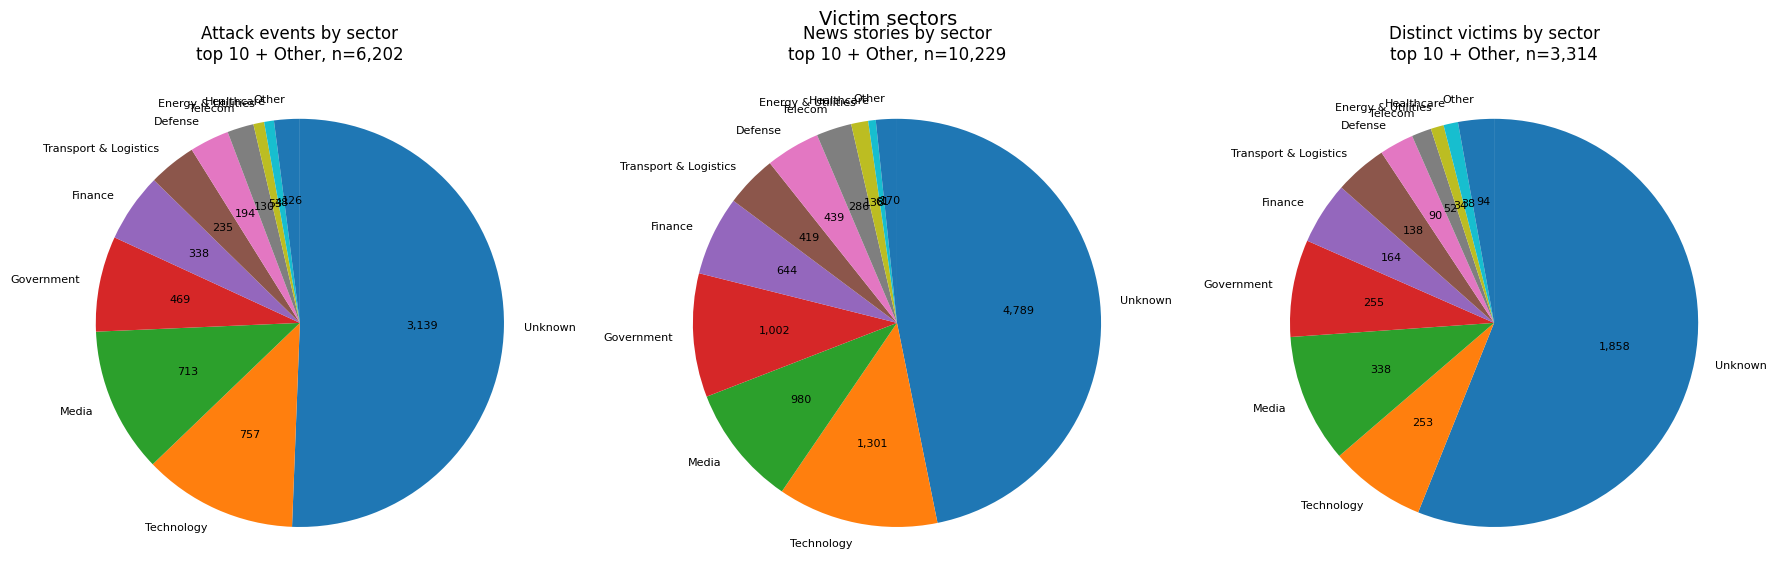

<Figure size 640x480 with 0 Axes>

In [50]:
import matplotlib.pyplot as plt

TOP_N = 10
COLUMNS = ['events', 'stories', 'victims']
TITLES = {'events': 'Attack events by sector',
          'stories': 'News stories by sector',
          'victims': 'Distinct victims by sector'}

by_sector = events_by_sector.copy()
unclassified = by_sector[by_sector.index.isna()][COLUMNS].sum()

by_sector.index = by_sector.index.fillna('Unknown')

top = by_sector.head(TOP_N)                      # already sorted by 'events'
rest = by_sector.iloc[TOP_N:]
if not rest.empty:
    top = pd.concat([top, rest[COLUMNS].sum().to_frame('Other').T]).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, column in zip(axes, COLUMNS):
    values = top[column]
    total = int(values.sum())
    values.plot.pie(
        ax=ax, labels=values.index, startangle=90, counterclock=False,
        autopct=lambda pct, total=total: f"{round(pct * total / 100):,}",
        textprops={'fontsize': 8},
    )
    ax.set_title(f"{TITLES[column]}\ntop {TOP_N} + Other, n={total:,}")
    ax.set_ylabel('')

fig.suptitle('Victim sectors', fontsize=14)
fig.tight_layout()
plt.show()

plt.savefig('./figs/victim_sectors_pie_charts.png', dpi=300, bbox_inches='tight')


Which victims are hit the most?

In [63]:
victims_highest_events = (attack_events[attack_events['target_label'] == 'Victim']
                        .groupby('target_name', dropna=False)
                        .agg(events=('event_id', 'size'), stories=('n_stories', 'sum'))
                        .sort_values('events', ascending=False))
print(victims_highest_events.head(10).to_string())

              events  stories
target_name                  
Cloudflare        49      107
Microsoft         45      116
Kaspersky         44      109
DDoS-Guard        35       90
Google            35       90
Telegram          29      100
Ukraine           29       84
Roskomnadzor      28       63
The Register      25       32
CISA              24       51


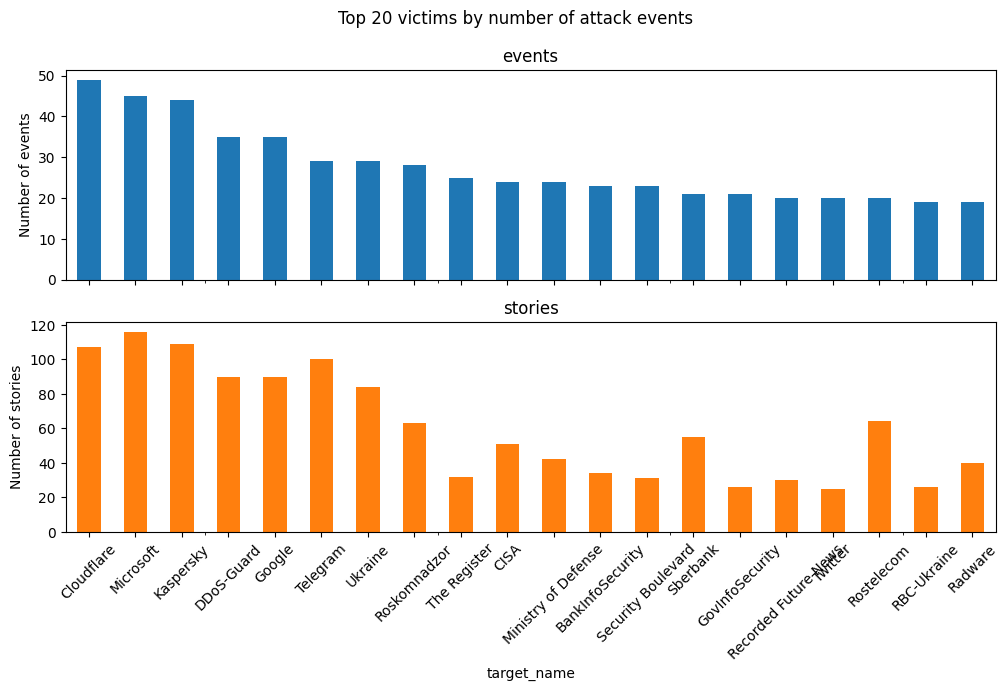

In [64]:

axes = (victims_highest_events.head(20)[['events', 'stories']]
        .plot.bar(subplots=True, figsize=(12, 6), legend=False, rot=45))

axes[0].set_ylabel('Number of events')
axes[1].set_ylabel('Number of stories')
fig = axes[0].figure
fig.suptitle('Top 20 victims by number of attack events')

fig.savefig('./figs/victims_highest_events.png', dpi=300, bbox_inches='tight')
plt.show()


Lets plot it on a map

In [61]:
import plotly.express as px

victim_country_counts = (
    attack_events[attack_events['target_label'] == 'Victim']
    .explode('countries')
    .dropna(subset=['countries'])
    .groupby('countries')
    .agg(
        attack_events=('event_id', 'nunique'),
        victims=('target_name', 'nunique'),
    )
    .reset_index()
    .rename(columns={'countries': 'country'})
)

fig = px.choropleth(
    victim_country_counts,
    locations='country',
    locationmode='country names',
    color='attack_events',
    hover_name='country',
    hover_data={'attack_events': True, 'victims': True, 'country': False},
    color_continuous_scale='Reds',
    title='Victim Countries by Number of Attack Events',
)

fig.update_layout(
    geo=dict(showframe=False, showcoastlines=True),
    coloraxis_colorbar_title='Attack events',
)
fig.show()

which groups attack the most?

In [65]:
attack_events.head()

,event_id,target_label,target_name,target_aliases,first_seen,last_seen,n_stories,rows,message_ids,titles,links,countries,groups,motives,costs,urls,ips,locations,span_days
0,E000000,Victim,Washington Examiner,[Washington Examiner],2015-09-16,2015-09-16,1,[12319],[75873],"[California hackers attack Kremlin, Putin's we...",[http://www.washingtonexaminer.com/california-...,"[Russia, United States]",[],[],[],[],[],"[California, Kremlin, United States]",0
1,E000001,Person,Churov,[Churov],2015-09-16,2015-09-16,1,[12319],[75873],"[California hackers attack Kremlin, Putin's we...",[http://www.washingtonexaminer.com/california-...,"[Russia, United States]",[],[],[],[],[],"[California, Kremlin, United States]",0
2,E000002,Person,Putin,[Putin],2015-09-17,2015-09-17,1,[12318],[75871],"[Russia: California hackers attack Kremlin, Pu...",[https://www.oodaloop.com/osint/cyber/2015/09/...,[Russia],[OODA Loop],[],[],[],[],"[Russia, California, Kremlin]",0
3,E000003,Person,Vladimir Putin,[Vladimir Putin],2015-09-18,2015-09-20,2,"[12330, 12314]","[76123, 75764]",[DDoS attacks hit The Kremlin and Vladimir Put...,[http://www.itproportal.com/2015/09/18/ddos-at...,[],[DDoS],[],[],[],[],[The Kremlin],2
4,E000004,Victim,Kremlin,[Kremlin],2015-09-18,2015-09-19,2,"[12329, 12327]","[76122, 76111]","[Kremlin hit by “very powerful” DDoS attack, K...",[https://www.thecybersecurityplace.com/kremlin...,[],[DDoS],[],[],[],[],[],1


                    events  stories
groups                             
DDoS                  1964     4659
Killnet                392      914
Russian                284      895
NoName                 172      218
DDOS                   137      575
KillNet                110      323
NoName057(16)          108      246
Russia                 106      366
Anonymous               94      309
Russian Cyber Army      70       72


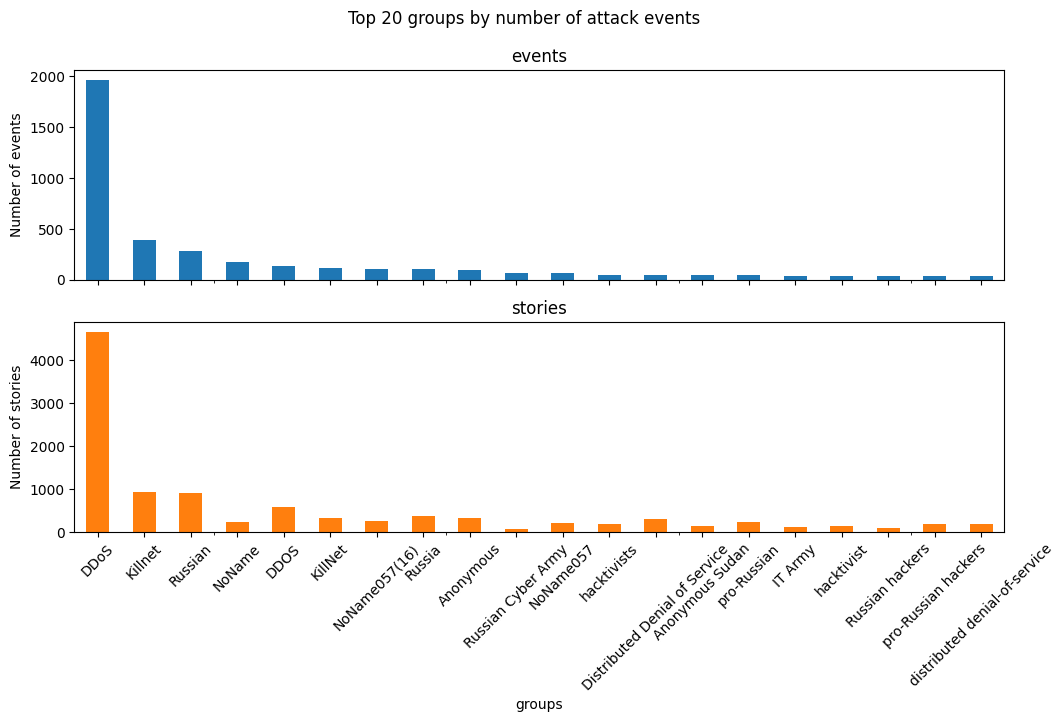

In [69]:
groups_highest_events = (attack_events[attack_events['target_label'] == 'Victim']
                         .explode('groups')
                         .dropna(subset=['groups'])
                         .groupby('groups')
                         .agg(events=('event_id', 'nunique'), stories=('n_stories', 'sum'))
                         .sort_values('events', ascending=False))

print(groups_highest_events.head(10).to_string())

axes = (groups_highest_events.head(20)[['events', 'stories']]
        .plot.bar(subplots=True, figsize=(12, 6), legend=False, rot=45))
axes[0].set_ylabel('Number of events')
axes[1].set_ylabel('Number of stories')
axes[0].figure.suptitle('Top 20 groups by number of attack events')

plt.savefig('./figs/groups_highest_events.png', dpi=300, bbox_inches='tight')


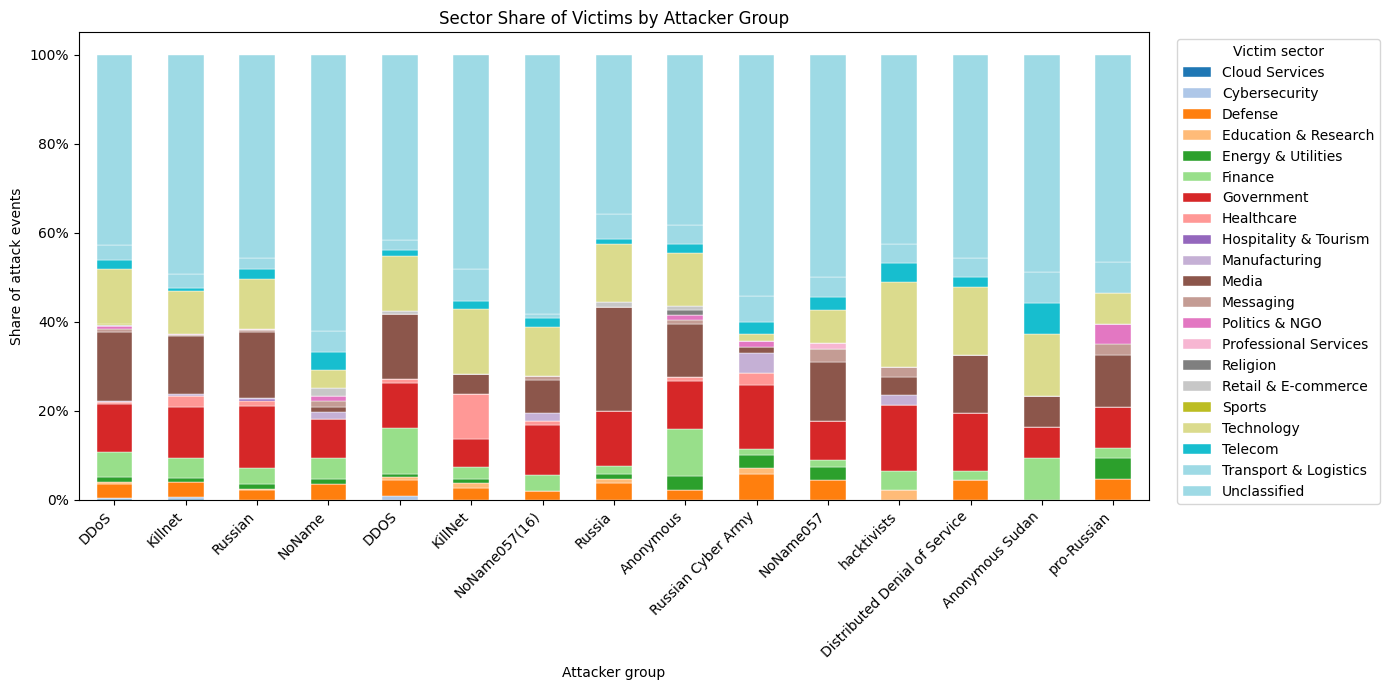

In [70]:
import matplotlib.pyplot as plt

group_sector = (
    attack_events[attack_events['target_label'].eq('Victim')]
    .explode('groups')
    .dropna(subset=['groups'])
    .assign(
        sector=lambda x: x['target_name'].map(victim_sectors['sector']).fillna('Unclassified')
    )
    .groupby(['groups', 'sector'])
    .size()
    .unstack(fill_value=0)
)

top_groups = group_sector.sum(axis=1).nlargest(15).index
group_sector = group_sector.loc[top_groups]


group_sector_share = group_sector.div(group_sector.sum(axis=1), axis=0)

ax = group_sector_share.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7),
    colormap='tab20',
    edgecolor='white',
    linewidth=0.3,
)

ax.set_title('Sector Share of Victims by Attacker Group')
ax.set_xlabel('Attacker group')
ax.set_ylabel('Share of attack events')
ax.yaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
ax.legend(title='Victim sector', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('./figs/group_sector_share.png', dpi=300, bbox_inches='tight')
plt.show()

### Graph in Neo4j

Each **group**, **victim** and **person** becomes a node with a `country` attribute, and every
attack becomes an `ATTACKED` relationship carrying the news message (message id, date, title,
content, link) plus the rest of the extracted metadata (motive, cost, url, ip, locations).

The extraction gives locations per *story*, not per *entity*, so a node's `country` is the
country it co-occurs with most often across all of its stories; the full candidate list stays
in `countries` so the choice remains inspectable.

In [20]:
%pip install -q neo4j

Note: you may need to restart the kernel to use updated packages.


In [71]:
NODE_LABELS = {'group': 'Group', 'victim': 'Victim', 'person': 'Person'}
content = df.loc[stories.index, 'Content']


def as_text(value):
    return value if isinstance(value, str) and value.strip() else None


country_votes = {}   
attacks = []

for event in attack_events.to_dict('records'):
    target = (event['target_label'], event['target_name'])
    actors = [(NODE_LABELS['group'], name) for name in event['groups']]

    for node in [target] + actors:
        country_votes.setdefault(node, Counter()).update(event['countries'])

    metadata = {
        'event_id': event['event_id'],
        'first_seen': event['first_seen'].date().isoformat(),
        'last_seen': event['last_seen'].date().isoformat(),
        'n_stories': int(event['n_stories']),
        'message_ids': event['message_ids'],
        'title': event['titles'][0] if event['titles'] else None,
        'titles': event['titles'],
        'content': as_text(content.at[event['rows'][0]]),
        'links': event['links'],
        'target_aliases': event['target_aliases'],
        'motives': event['motives'],
        'costs': event['costs'],
        'urls': event['urls'],
        'ips': event['ips'],
        'locations': event['locations'],
        'countries': event['countries'],
    }

    for actor_label, actor_name in actors:
        if (actor_label, actor_name) == target:
            continue 
        attacks.append({
            'source_label': actor_label, 'source_name': actor_name,
            'target_label': target[0], 'target_name': target[1],
            **metadata,
        })

def enrichment_of(label, name):
    if label != 'Victim' or name not in victim_sectors.index:
        return {}
    row = victim_sectors.loc[name].to_dict()
    return {key: (None if pd.isna(value) else value) for key, value in row.items()}


def node_properties(label, name, votes):
    """Node attributes, with Wikidata filling in what the stories left blank."""
    enrichment = enrichment_of(label, name)
    country = votes.most_common(1)[0][0] if votes else None
    country_source = 'stories' if country else None
    if not country and enrichment.get('wikidata_country'):
        country, country_source = enrichment['wikidata_country'], 'wikidata'
    return {
        'label': label, 'name': name,
        'country': country, 'country_source': country_source,
        'countries': [country for country, _ in votes.most_common()],
        'sector': enrichment.get('sector'),
        'sector_source': enrichment.get('sector_source'),
        'wikidata_id': enrichment.get('wikidata_id'),
        'wikidata_description': enrichment.get('wikidata_description'),
    }


nodes = [node_properties(label, name, votes) for (label, name), votes in country_votes.items()]

print(f"{len(nodes)} nodes {dict(Counter(node['label'] for node in nodes))}, "
      f"{len(attacks)} ATTACKED relationships from {len(attack_events)} events")
print(f"{(attack_events['groups'].map(len) == 0).sum()} events name no group and so produce no edge")
print(f"{sum(1 for node in nodes if node['sector'])} nodes carry a sector, "
      f"{sum(1 for node in nodes if node['country_source'] == 'wikidata')} got their country "
      f"from Wikidata")


5259 nodes {'Victim': 3314, 'Person': 676, 'Group': 1269}, 7694 ATTACKED relationships from 7076 events
2050 events name no group and so produce no edge
1471 nodes carry a sector, 211 got their country from Wikidata


In [ ]:
from neo4j import GraphDatabase

NEO4J_URI = os.environ.get('NEO4J_URI', 'bolt://localhost:7687')
NEO4J_USER = os.environ.get('NEO4J_USER', 'neo4j')
NEO4J_DATABASE = os.environ.get('NEO4J_DATABASE', 'neo4j')

driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))
driver.verify_connectivity()
print(f"connected to {NEO4J_URI}")

connected to bolt://localhost:7687


In [73]:
with driver.session(database=NEO4J_DATABASE) as session:
    for label in NODE_LABELS.values():
        session.run(f"CREATE CONSTRAINT {label.lower()}_name IF NOT EXISTS "
                    f"FOR (n:{label}) REQUIRE n.name IS UNIQUE")
print('constraints in place')

constraints in place


In [74]:

RESET_GRAPH = True

if RESET_GRAPH:
    with driver.session(database=NEO4J_DATABASE) as session:
        session.run("MATCH (n) WHERE n:Group OR n:Victim OR n:Person DETACH DELETE n")
    print('existing Group/Victim/Person nodes removed')

existing Group/Victim/Person nodes removed


In [75]:

NODE_QUERY = """
UNWIND $rows AS row
MERGE (n:{label} {{name: row.name}})
SET n.country = row.country,
    n.country_source = row.country_source,
    n.countries = row.countries,
    n.sector = row.sector,
    n.sector_source = row.sector_source,
    n.wikidata_id = row.wikidata_id,
    n.wikidata_description = row.wikidata_description
"""

ATTACK_QUERY = """
UNWIND $rows AS row
MATCH (source:{source_label} {{name: row.source_name}})
MATCH (target:{target_label} {{name: row.target_name}})
MERGE (source)-[attack:ATTACKED {{event_id: row.event_id}}]->(target)
SET attack.first_seen = date(row.first_seen),
    attack.last_seen = date(row.last_seen),
    attack.n_stories = row.n_stories,
    attack.message_ids = row.message_ids,
    attack.title = row.title,
    attack.titles = row.titles,
    attack.content = row.content,
    attack.links = row.links,
    attack.target_aliases = row.target_aliases,
    attack.motives = row.motives,
    attack.costs = row.costs,
    attack.urls = row.urls,
    attack.ips = row.ips,
    attack.locations = row.locations,
    attack.countries = row.countries
"""


def batches(rows, size=1000):
    for start in range(0, len(rows), size):
        yield rows[start:start + size]


def group_by(rows, *keys):
    grouped = {}
    for row in rows:
        grouped.setdefault(tuple(row[key] for key in keys), []).append(row)
    return grouped


with driver.session(database=NEO4J_DATABASE) as session:
    for (label,), rows in group_by(nodes, 'label').items():
        for batch in batches(rows):
            session.run(NODE_QUERY.format(label=label), rows=batch)
        print(f"{len(rows):>6}  :{label} nodes")

    for (source_label, target_label), rows in group_by(attacks, 'source_label', 'target_label').items():
        query = ATTACK_QUERY.format(source_label=source_label, target_label=target_label)
        for batch in batches(rows):
            session.run(query, rows=batch)
        print(f"{len(rows):>6}  (:{source_label})-[:ATTACKED]->(:{target_label})")

  3314  :Victim nodes
   676  :Person nodes
  1269  :Group nodes
   866  (:Group)-[:ATTACKED]->(:Person)
  6828  (:Group)-[:ATTACKED]->(:Victim)


In [76]:
with driver.session(database=NEO4J_DATABASE) as session:
    print(session.run("""
        MATCH (n) WHERE n:Group OR n:Victim OR n:Person
        RETURN labels(n)[0] AS label, count(*) AS nodes,
               count(n.country) AS with_country, count(n.sector) AS with_sector
        ORDER BY label
    """).to_df().to_string(index=False))

    print()
    print(session.run("""
        MATCH (g:Group)-[a:ATTACKED]->(t)
        RETURN g.name AS group, g.country AS group_country,
               t.name AS target, t.country AS target_country, t.sector AS target_sector,
               a.first_seen AS first_seen, a.n_stories AS stories, a.title AS title
        ORDER BY a.first_seen DESC
        LIMIT 10
    """).to_df().to_string(index=False))

 label  nodes  with_country  with_sector
 Group   1269           950            0
Person    676           445            0
Victim   3314          2491         1471

         group group_country                  target target_country         target_sector first_seen  stories                                                                       title
          DDoS        Russia             Nova Poshta        Ukraine Transport & Logistics 2026-10-01        4 Nova Poshta warns of possible temporary disruptions to services due to DDoS
Forbes Ukraine       Ukraine             Nova Poshta        Ukraine Transport & Logistics 2026-10-01        4 Nova Poshta warns of possible temporary disruptions to services due to DDoS
 United Russia        Russia               Chosunbiz            NaN                   NaN 2026-09-26        1         United Russia dominates post-war election, seats veterans in Duma -
          DDoS        Russia               Chosunbiz            NaN                   NaN 2

In [77]:
driver.close()